# **CSI 4142: Assignment 3** </br> Predictive analysis

## **Group members**
**Group 75**

| Name | Student ID |
|------|------------|
| Zixin Fan | 300296371 |
| Solin Maaroof | 300250903 | 

## **Task distribution**
- Zixin Fan: Regression - data cleaning, exploratory data analysis (EDA), outlier detection, linear regression modeling, feature engineering, and result analysis.

- Solin Maaroof: Classification - data preprocessing, decision tree modeling, model evaluation, and result analysis.

## **Libraries and Packages**

In [256]:
import pandas as pd # For data manipulation and analysis using DataFrames
import numpy as np # For numberical computing and array/ matrix operations
import seaborn as sns # For statistical data visualization with better styling
import matplotlib.pyplot as plt # For creating basic plots and visualizations
from sklearn.neighbors import LocalOutlierFactor # import lof model for outlier detection
from sklearn.model_selection import train_test_split # train / validation / test split
from sklearn.linear_model import LinearRegression  # linear regression model
from sklearn.model_selection import cross_val_score # for performing cross-validation and evaluating model performance
from sklearn.metrics import mean_squared_error,r2_score # evaluation metrics
from sklearn.model_selection import KFold # for manually splitting data into k folds for cross-validation

## **Dataset 1**: Medical Cost Personal

### Description
- **Dataset Name:** Medical Cost Personal Dataset
- **Owner:** Miri Choi (Kaggle)
- **Purpose:** This dataset contains demographic and health-related information of individuals along with their medical insurance charges.
- **Shape:** This dataset contains 1338 rows and 7 columns, as shown by dataset.shape.
- **Features:**
  - Age (Numerical): Age of the primary beneficiary.
  - Sex (Categorical): Gender of the insurance beneficiary (male or female).
  - BMI (Numerical): Body mass index, a measure of body weight relative to height.
  - Children (Numerical): Number of dependents covered by health insurance.
  - Smoker (Categorical): Indicates whether the beneficiary is a smoker (yes or no).
  - Region (Categorical): Residential region in the United States (northeast, southeast, southwest, northwest).
  - Charges (Numerical): Individual medical costs billed by health insurance.


## Regression Empirical Study with Linear Regression

In [257]:
dataset1=pd.read_csv( "https://raw.githubusercontent.com/Zixin-Fan/CSI4142-A3/main/insurance.csv") # Read 'insurance.csv' from github
dataset1.head() # show the first 5 rows of the dataset

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [258]:
dataset1.shape

(1338, 7)

### a) Data Cleaning

In [259]:
# create a working copy of the dataset
cleaned_dataset1=dataset1.copy()

#### Check data type errors

In [260]:
numeric_cols=["age","bmi","children","charges"]
for col in numeric_cols:
    cleaned_dataset1[col]=pd.to_numeric(cleaned_dataset1[col],errors="coerce")
invalid_numeric_rows=cleaned_dataset1[cleaned_dataset1[numeric_cols].isna().any(axis=1)]
invalid_numeric_rows

,age,sex,bmi,children,smoker,region,charges


This check focuses on numerical attributes because regression models require numeric input variables. Categorical attributes will be validated separately in the format and look-up checks. Numeric columns were converted to numeric format. Any non-numeric values would become NaN and be flagged as type errors. No such errors were found in the dataset.

#### Check range errors

In [261]:
invalid_range=cleaned_dataset1[
    (cleaned_dataset1["age"]<=0)|
    (cleaned_dataset1["bmi"]<=0)|
    (cleaned_dataset1["children"]<0)|
    (cleaned_dataset1["charges"]<0)
]
invalid_range

,age,sex,bmi,children,smoker,region,charges


This check verifies that numerical values fall within valid ranges. Negative or impossible values are considered range errors. No such errors were found in the dataset.

#### Check format errors

In [262]:
format_errors=cleaned_dataset1[
    (cleaned_dataset1["sex"].str.lower()!=cleaned_dataset1["sex"])|
    (cleaned_dataset1["smoker"].str.lower()!=cleaned_dataset1["smoker"])|
    (cleaned_dataset1["region"].str.lower()!=cleaned_dataset1["region"])
]
format_errors

,age,sex,bmi,children,smoker,region,charges


Categorical values were checked for formatting consistency. All values already follow the expected format. No such errors were detected.

#### Check consistency errors

In [263]:
consistencyCheckDataset=cleaned_dataset1.copy()
avg_charges=consistencyCheckDataset["charges"].mean()
consistency_errors=consistencyCheckDataset[
    (consistencyCheckDataset["smoker"]=="yes")&
    (consistencyCheckDataset["charges"]<avg_charges)
]
consistency_errors.head()

,age,sex,bmi,children,smoker,region,charges
250,18,male,17.29,2,yes,northeast,12829.4551


This check verifies whether smokers have unusually low medical charges compared to the dataset average. One row was flagged by the checker; however, this does not necessarily represent a real data error but may indicate an unusual pattern worth inspecting.

#### Check uniqueness errors

In [264]:
duplicate_rows=cleaned_dataset1[
    cleaned_dataset1.duplicated()
]
duplicate_rows

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


Duplicate rows were checked to ensure each record represents a unique observation. However, different individuals may share identical attributes, so such cases do not necessarily indicate data errors.

#### Check presence errors

In [265]:
missing_values=cleaned_dataset1[
    cleaned_dataset1.isna().any(axis=1)
]
missing_values

,age,sex,bmi,children,smoker,region,charges


This check verifies whether any missing values exist in the dataset. No such errors were detected.

#### Check length errors

In [266]:

lengthCheckDataset=cleaned_dataset1.copy()
invalid_length=lengthCheckDataset[
    (~lengthCheckDataset["sex"].str.len().isin([4,6]))|
    (~lengthCheckDataset["smoker"].str.len().isin([2,3]))|
    (~lengthCheckDataset["region"].str.len().isin([9]))
]
invalid_length

,age,sex,bmi,children,smoker,region,charges


String lengths were validated to ensure categorical values follow the expected format. No such errors were detected.

#### Check look-up errors

In [267]:

valid_sex=["male","female"]
valid_smoker=["yes","no"]
valid_region=["northeast","northwest","southeast","southwest"]
invalid_lookup=cleaned_dataset1[
    (~cleaned_dataset1["sex"].isin(valid_sex))|
    (~cleaned_dataset1["smoker"].isin(valid_smoker))|
    (~cleaned_dataset1["region"].isin(valid_region))
]
invalid_lookup

,age,sex,bmi,children,smoker,region,charges


Categorical attributes were validated against predefined valid categories. No such errors were detected.

### Conclusion
After performing data validation checks including data type, range, format, consistency, uniqueness, presence, length, and look-up validation, no major data quality issues were identified in the dataset. Therefore, the dataset is considered suitable for further analysis.

### b) Categorical feature encoding

In [268]:
# categorical feature encoding using one-hot encoding
encoded_dataset1=cleaned_dataset1.copy()
# categorical columns
categorical_cols=["sex","smoker","region"]
# convert each category into separate columns (True/False by default)
encoded_dataset1=pd.get_dummies(encoded_dataset1, # dataset to transform
                                columns=categorical_cols, # columns to encode: ["sex","smoker","region"]
                                drop_first=True) # drop one category to avoid multicollinearity e.g. only keep sex_male, 1 represents male, 0 represents female

# convert only dummy columns to 0/1
dummy_cols=[col for col in encoded_dataset1.columns if col not in ["age","bmi","children","charges"]]
encoded_dataset1[dummy_cols]=encoded_dataset1[dummy_cols].astype(int)

encoded_dataset1.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


Categorical variables (sex, smoker, and region) were transformed into numerical features using one-hot encoding. One category was dropped to avoid multicollinearity in linear regression, meaning that no dummy variable can be expressed as a linear combination of the others.

### c) EDA and Outlier detection

#### EDA: visualize potential outliers

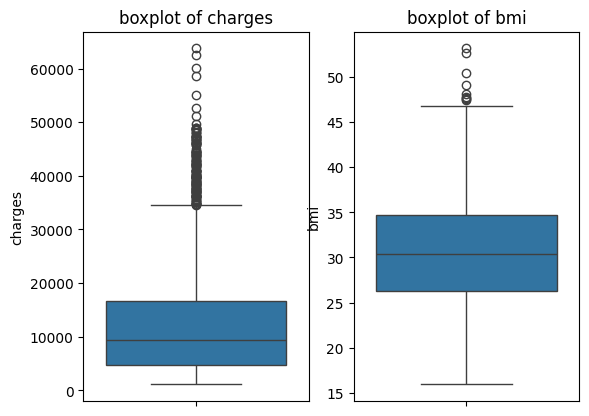

In [269]:
# boxplot for charges
plt.subplot(1,2,1) # place two boxplots in the same plot
sns.boxplot(y=encoded_dataset1["charges"])
plt.title("boxplot of charges")

# boxplot for bmi
plt.subplot(1,2,2)
sns.boxplot(y=encoded_dataset1["bmi"])
plt.title("boxplot of bmi")

plt.show()

EDA focused on continuous features likely to contain extreme values. The features "charges" and "bmi" were analyzed, while "age"(fixed range) and "children"(discrete) were not considered critical for outlier detection.
- The boxplot of "charges" shows a large number of potential outliers due to its right-skewed distribution. However, these extreme values may represent real observations rather than errors. Therefore, LOF will be applied to identify true outliers more reliably.
- The feature "bmi" shows fewer outliers and appears more normally distributed.

#### LOF: applied LOF on selected feature

In [270]:
lof=LocalOutlierFactor(n_neighbors=20) # initialize lof model; n_neighbors=20 was used as a standard choice to capture local density patterns (balance sensitivity to noise and robustness)
lof_labels=lof.fit_predict(encoded_dataset1[["charges"]]) # fit model and predict outliers; output: 1=normal point, -1=outlier
outliers=encoded_dataset1[lof_labels==-1] # extract rows identified as outliers
outliers.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
34,28,36.400,1,51194.55914,1,1,0,0,1
77,21,35.530,0,1532.46970,1,0,0,1,0
199,64,39.330,0,14901.51670,0,0,0,0,0
374,20,33.330,0,1391.52870,1,0,0,1,0
380,27,17.955,2,15006.57945,0,1,0,0,0


#### Decision: remove outliers from “charges” detected by LOF

In [271]:
dataset1_no_outliers=encoded_dataset1[lof_labels!=-1]

Based on EDA, the feature "charges" showed a large number of potential outliers, while "bmi" contained only a few. Therefore, LOF was applied only to "charges" to detect abnormal observations. The identified outliers were removed to reduce their influence on the model, although some of these observations may represent valid extreme values. The "bmi" feature was kept unchanged, as its extreme values were limited and likely valid.

### d) Predictive analysis

#### Linear regression: explore the LinearRegression method suggested in scikit-learn

Linear Regression models the relationship between input features and the target variable as a linear combination: y = β₀ + β₁x₁ + β₂x₂ + ... + βₙxₙ + ε

where β₀ is the intercept, βᵢ are the coefficients, and ε represents the error term.

The model parameters are learned by minimizing the residual error between predicted and actual values, typically using a least squares approach.

The following code is provided for illustration purposes.

```python
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
##### Train the model
model=LinearRegression()
model.fit(X_train, y_train)
##### Make predictions
y_pred = model.predict(X_val)
##### Evaluate performance
mse=mean_squared_error(y_val, y_pred)
lmse=mean_squared_error(np.log(y_val+1),np.log(y_pred+1))
r2=r2_score(y_val, y_pred)

The model is evaluated using MSE, LMSE, and R² score.

MSE measures the average squared difference between predicted and actual values, indicating how close the predictions are to the true values.

LMSE applies a logarithmic transformation to the target variable before computing the error, which can be useful when the target variable is skewed.

R² represents the proportion of variance in the target variable that is explained by the model.

MSE penalizes larger errors more heavily due to the squaring term, making it sensitive to outliers, while R² provides an intuitive measure of how well the model explains the variability of the data.

#### Other regularized regression methods exist in scikit-learn

- Ridge Regression adds an L2 penalty to shrink coefficients and reduce overfitting: minimize ‖y - Xw‖² + λ‖w‖²

- Lasso Regression adds an L1 penalty, which can shrink some coefficients to zero (feature selection): minimize ‖y - Xw‖² + λ‖w‖₁

- Elastic Net combines both L1 and L2 penalties: minimize ‖y - Xw‖² + λ₁‖w‖₁ + λ₂‖w‖²

### e) Feature Engineering

#### Add features to encoded_dataset1

In [272]:
# create a copy for feature engineering
dataset1_feature_base=encoded_dataset1.copy()
# feature combining age and bmi
dataset1_feature_base["bmi_age"]=dataset1_feature_base["bmi"]*dataset1_feature_base["age"]
# feature combining bmi and smoker status
dataset1_feature_base["bmi_smoker"]=dataset1_feature_base["bmi"]*dataset1_feature_base["smoker_yes"]
dataset1_feature_base.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_age,bmi_smoker
0,19,27.900,0,16884.92400,0,1,0,0,1,530.100,27.9
1,18,33.770,1,1725.55230,1,0,0,1,0,607.860,0.0
2,28,33.000,3,4449.46200,1,0,0,1,0,924.000,0.0
3,33,22.705,0,21984.47061,1,0,1,0,0,749.265,0.0
4,32,28.880,0,3866.85520,1,0,1,0,0,924.160,0.0


#### Add features to dataset_no_outliers

In [273]:
dataset1_feature=dataset1_no_outliers.copy()
dataset1_feature["bmi_age"]=dataset1_feature["bmi"]*dataset1_feature["age"]
dataset1_feature["bmi_smoker"]=dataset1_feature["bmi"]*dataset1_feature["smoker_yes"]
dataset1_feature.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_age,bmi_smoker
0,19,27.900,0,16884.92400,0,1,0,0,1,530.100,27.9
1,18,33.770,1,1725.55230,1,0,0,1,0,607.860,0.0
2,28,33.000,3,4449.46200,1,0,0,1,0,924.000,0.0
3,33,22.705,0,21984.47061,1,0,1,0,0,749.265,0.0
4,32,28.880,0,3866.85520,1,0,1,0,0,924.160,0.0


The first feature, `bmi_age`, is created by multiplying(stronger than adding) age and BMI, because medical costs are usually affected by both age and body condition at the same time.

The second feature, `bmi_smoker`, is created by multiplying(stronger than adding) BMI and smoking status, because smoking is known to significantly increase insurance charges. 

In the next section, we will compare models with and without these new features to see if they improve prediction performance.

### f) Empirical study

#### a. split dataset

In [274]:
y=encoded_dataset1["charges"] # target variable
x=encoded_dataset1.drop(columns=["charges"]) # features
# x_test,y_test(15%)->test dataset; x_temp，y_temp-> train_reduced (remaining)
# random_state=42: ensures reproducibility (same split every time we run the code)
x_rem,x_test,y_rem,y_test=train_test_split(x,y,test_size=0.15,random_state=42) # 15% of the data is reserved as the test set to simulate future unseen data
# validation dataset(20% of the remaining); the rest is training dataset
x_train,x_val,y_train,y_val=train_test_split(x_rem,y_rem,test_size=0.2,random_state=42) # 0.2*remaining=validation, the rest is the training dataset

#### b. decide on some evaluation metrics

We use MSE, LMSE, and R² as evaluation metrics.

#### c. linear regression with baseline settings

In [275]:
model=LinearRegression() # create a linear regression model with default settings (baseline)

# perform 4-fold cross-validation on the training data
# the training dataset is split into 4 parts, and each time, 3 parts are used for training and 1 part is used for validation
# this process is repeated 4 times->4 MSE values, and we will average them to get mse_scores
# MSE
mse_scores=-cross_val_score(model,x_train,y_train,cv=4,scoring='neg_mean_squared_error') # the returned value is negative, so we add minus sign to convert it
print("Baseline MSE:",np.mean(mse_scores))

# LMSE
# initialize KFold to perform 4-fold cross-validation
# shuffle=True ensures randomness, random_state=42 ensures reproducibility
kf=KFold(n_splits=4,shuffle=True,random_state=42)
lmse_scores=[]

# iterate over each fold
# each time: use part of data for training and the remaining part for validation
for train_idx,val_idx in kf.split(x_train):
    # split training data into current fold's training and validation sets
    X_tr,X_val=x_train.iloc[train_idx],x_train.iloc[val_idx]
    y_tr,y_val=y_train.iloc[train_idx],y_train.iloc[val_idx]
    # train the model on the current training fold
    model.fit(X_tr,y_tr)
    # make predictions on the validation fold
    y_pred=model.predict(X_val)
    # ensure predictions are non-negative to avoid invalid values in log1p
    y_pred_safe=np.maximum(y_pred,0)
    # apply log transformation to both true values and predictions, then compute MSE
    lmse=mean_squared_error(np.log1p(y_val),np.log1p(y_pred_safe))
    lmse_scores.append(lmse)
lmse=np.mean(lmse_scores)
print("Baseline LMSE:",lmse)

# R square
r2_scores=cross_val_score(model,x_train,y_train,cv=4,scoring='r2')
r2=np.mean(r2_scores)
print("Baseline r square:",r2)

Baseline MSE: 40150390.50249188
Baseline LMSE: 1.326346414651969
Baseline r square: 0.7324065545029632


#### d. different system configurations

##### 1. Feature Only

In [276]:
# taget variable and features
y=dataset1_feature_base["charges"]
x=dataset1_feature_base.drop(columns=["charges"])
# split test/validation/train
x_rem,x_test,y_rem,y_test=train_test_split(x,y,test_size=0.15,random_state=42)
x_train,x_val,y_train,y_val=train_test_split(x_rem,y_rem,test_size=0.2,random_state=42)
model=LinearRegression()

# MSE
mse_scores=-cross_val_score(model,x_train,y_train,cv=4,scoring='neg_mean_squared_error')
print("Config1 MSE:",np.mean(mse_scores))

# LMSE
kf=KFold(n_splits=4,shuffle=True,random_state=42)
lmse_scores=[]
for train_idx,val_idx in kf.split(x_train):
    X_tr,X_val=x_train.iloc[train_idx],x_train.iloc[val_idx]
    y_tr,y_val=y_train.iloc[train_idx],y_train.iloc[val_idx]
    model.fit(X_tr,y_tr)
    y_pred=model.predict(X_val)
    y_pred_safe=np.maximum(y_pred,0)
    lmse=mean_squared_error(np.log1p(y_val),np.log1p(y_pred_safe))
    lmse_scores.append(lmse)
lmse=np.mean(lmse_scores)
print("Config1 LMSE:",lmse)

# R2
r2_scores=cross_val_score(model,x_train,y_train,cv=4,scoring='r2')
r2=np.mean(r2_scores)
print("Config1 R2:",r2)

Config1 MSE: 25269539.430918664
Config1 LMSE: 0.17569447183032685
Config1 R2: 0.8333583564688104


##### 2. Outlier Removal Only

In [277]:
# taget variable and features
y=dataset1_no_outliers["charges"]
x=dataset1_no_outliers.drop(columns=["charges"])
# split test/validation/train
x_rem,x_test,y_rem,y_test=train_test_split(x,y,test_size=0.15,random_state=42)
x_train,x_val,y_train,y_val=train_test_split(x_rem,y_rem,test_size=0.2,random_state=42)
model=LinearRegression()

# MSE
mse_scores=-cross_val_score(model,x_train,y_train,cv=4,scoring='neg_mean_squared_error')
print("Config2 MSE:",np.mean(mse_scores))

# LMSE
kf=KFold(n_splits=4,shuffle=True,random_state=42)
lmse_scores=[]
for train_idx,val_idx in kf.split(x_train):
    X_tr,X_val=x_train.iloc[train_idx],x_train.iloc[val_idx]
    y_tr,y_val=y_train.iloc[train_idx],y_train.iloc[val_idx]
    model.fit(X_tr,y_tr)
    y_pred=model.predict(X_val)
    y_pred_safe=np.maximum(y_pred,0)
    lmse=mean_squared_error(np.log1p(y_val),np.log1p(y_pred_safe))
    lmse_scores.append(lmse)
lmse=np.mean(lmse_scores)
print("Config2 LMSE:",lmse)

# R2
r2_scores=cross_val_score(model,x_train,y_train,cv=4,scoring='r2')
r2=np.mean(r2_scores)
print("Config2 R2:",r2)

Config2 MSE: 34825567.49891765
Config2 LMSE: 0.6639878592358723
Config2 R2: 0.7283193614646488


##### 3. Feature + Outlier Removal

In [278]:
# taget variable and features
y=dataset1_feature["charges"]
x=dataset1_feature.drop(columns=["charges"])
# split test/validation/train
x_rem,x_test,y_rem,y_test=train_test_split(x,y,test_size=0.15,random_state=42)
x_train,x_val,y_train,y_val=train_test_split(x_rem,y_rem,test_size=0.2,random_state=42)
model=LinearRegression()

# MSE
mse_scores=-cross_val_score(model,x_train,y_train,cv=4,scoring='neg_mean_squared_error')
print("Config3 MSE:",np.mean(mse_scores))

# LMSE
kf=KFold(n_splits=4,shuffle=True,random_state=42)
lmse_scores=[]
for train_idx,val_idx in kf.split(x_train):
    X_tr,X_val=x_train.iloc[train_idx],x_train.iloc[val_idx]
    y_tr,y_val=y_train.iloc[train_idx],y_train.iloc[val_idx]
    model.fit(X_tr,y_tr)
    y_pred=model.predict(X_val)
    y_pred_safe=np.maximum(y_pred,0)
    lmse=mean_squared_error(np.log1p(y_val),np.log1p(y_pred_safe))
    lmse_scores.append(lmse)
lmse=np.mean(lmse_scores)
print("Config3 LMSE:",lmse)

# R2
r2_scores=cross_val_score(model,x_train,y_train,cv=4,scoring='r2')
r2=np.mean(r2_scores)
print("Config3 R2:",r2)

Config3 MSE: 22771811.786157936
Config3 LMSE: 0.18295136060732742
Config3 R2: 0.821773574903363


#### e. apply best configuration

In [279]:
# use feature dataset
x=dataset1_feature_base.drop(columns=["charges"])
y=dataset1_feature_base["charges"]
# same split (important!)
x_rem,x_test,y_rem,y_test=train_test_split(x,y,test_size=0.15,random_state=42)
x_train,x_val,y_train,y_val=train_test_split(x_rem,y_rem,test_size=0.2,random_state=42)
# combine train + validation
x_train_val=pd.concat([x_train,x_val])
y_train_val=pd.concat([y_train,y_val])
# train final model
final_model=LinearRegression()
final_model.fit(x_train_val,y_train_val)
# predict on test set
y_test_pred=final_model.predict(x_test)
# safe for LMSE
y_test_pred_safe=np.maximum(y_test_pred,0)
# compute metrics
# mse
test_mse=mean_squared_error(y_test,y_test_pred)
# lmse
test_lmse=mean_squared_error(np.log1p(y_test),np.log1p(y_test_pred_safe))
# r square
test_r2=r2_score(y_test,y_test_pred)
print("Final Test MSE:",test_mse)
print("Final Test LMSE:",test_lmse)
print("Final Test R2:",test_r2)

Final Test MSE: 21184785.336568885
Final Test LMSE: 0.14463768521393605
Final Test R2: 0.8608714708539795


### g) Result analysis

#### a. Analyse the obtained results

| Configuration | MSE | LMSE | R² |
|---|---:|---:|---:|
| Baseline | 40150390.50249188 | 1.326346414651969 | 0.7324065545029632 |
| Feature Only  | 25269539.430918664 | 0.17569447183032685 | 0.8333583564688104 |
| Outlier Removal Only  | 34825567.49891765 | 0.6639878592358723 | 0.7283193614646488 |
| Feature + Outlier Removal  | 22771811.786157936 | 0.18295136060732742 | 0.821773574903363 |
| Final Test (Best Config: Feature Only) | 21184785.336568885 | 0.14463768521393605 | 0.8608714708539795 |

- Baseline: worst performance, with the highest MSE and LMSE, and the lowest R².

- Feature only: clear improvement over baseline, with lower MSE, and the best LMSE and R² among three configurations.

- Outlier removal only: relatively poor performance, similar to or slightly worse than the baseline, showing that removing outliers alone is not effective.

- Feature + outlier removal: achieves the lowest MSE, but LMSE and R² are slightly worse than Config1.

- Best configuration: feature only, since LMSE and R² are better, indicating stronger overall model performance.

- Final test results: best across all metrics (MSE, LMSE, and R²), showing that the model generalizes well and benefits from training on more data.

#### b. The impact of outlier detection and feature aggregation

- Outlier detection does not improve performance in this dataset. This is because some extreme values are actually normal in real life. For example, a person with severe illness may have very high medical costs. If we remove these data points, the model loses important information and performs worse.

- Feature engineering improves model performance because it helps capture more meaningful relationships between variables. For example, combining features such as BMI and age or smoker status allows the model to better understand how these factors together influence medical costs. 

- As a result, feature engineering is beneficial, while outlier removal may be harmful in this context.

#### c. How the results on the unseen test set compare to the cross-validation results

The test set results are consistent with the cross-validation results, showing that the selected configuration (feature only) is reliable. The performance on the test set is slightly better than the cross-validation results in terms of MSE, LMSE, and R². This improvement is expected because the final model was trained on a larger dataset (train + validation), allowing it to learn more stable patterns. The results indicate that the model generalizes well to unseen data and does not suffer from overfitting.

## **References**

Some code snippets and explanations were generated with the assistance of generative AI.
Queries include:
- understand how `.get_dummies` performs one-hot encoding
- understand how to apply LOF using `LocalOutlierFactor` from `sklearn.neighbors`
- how to split dataset into train, validation, and test sets using `train_test_split`
- how to apply Linear Regression using `LinearRegression()` in scikit-learn
- how to evaluate regression models using `mean_squared_error` and `r2_score`
- how to perform 4-fold cross-validation using `cross_val_score`
- how to manually compute LMSE using KFold cross-validation by training the model on each fold, predicting on the validation fold, and applying mean_squared_error(np.log1p(y_true), np.log1p(y_pred))


Datasets:
- Dataset 1: https://www.kaggle.com/datasets/mirichoi0218/insurance
- Dataset 2: 

Official documentation:
- https://pandas.pydata.org/docs/  
- https://numpy.org/doc/  
- https://matplotlib.org/stable/tutorials/index
- https://seaborn.pydata.org/tutorial.html